<a href="https://colab.research.google.com/github/vandanasri/MLProjectRepo/blob/main/p04-Vandana/pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [106]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [107]:
# import New York City Airbnb Open Dataset
df = pd.read_csv("/content/AB_NYC_2019.csv", skipinitialspace=True)

In [108]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [109]:
# dropping of unwanted columns which don't effect on Target value
df.drop(columns=['id', 'name', 'host_id', 'host_name','last_review'], axis=1, inplace = True)
df.columns

Index(['neighbourhood_group', 'neighbourhood', 'latitude', 'longitude',
       'room_type', 'price', 'minimum_nights', 'number_of_reviews',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='object')

In [110]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 11 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   neighbourhood_group             48895 non-null  object 
 1   neighbourhood                   48895 non-null  object 
 2   latitude                        48895 non-null  float64
 3   longitude                       48895 non-null  float64
 4   room_type                       48895 non-null  object 
 5   price                           48895 non-null  int64  
 6   minimum_nights                  48895 non-null  int64  
 7   number_of_reviews               48895 non-null  int64  
 8   reviews_per_month               38843 non-null  float64
 9   calculated_host_listings_count  48895 non-null  int64  
 10  availability_365                48895 non-null  int64  
dtypes: float64(3), int64(5), object(3)
memory usage: 4.1+ MB


In [111]:
df.corr(numeric_only=True)['price'].sort_values(ascending=False)

,price
price,1.000000
availability_365,0.081829
calculated_host_listings_count,0.057472
minimum_nights,0.042799
latitude,0.033939
reviews_per_month,-0.030608
number_of_reviews,-0.047954
longitude,-0.150019


In [115]:
# Splitting data into train and test
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [116]:
# Extracted categorical columns
cat_col = X_train.select_dtypes(include='object').columns
cat_col

Index(['neighbourhood_group', 'neighbourhood', 'room_type'], dtype='object')

In [117]:
# Extracted continuous columns
num_col = X_train.select_dtypes(include=np.number).columns
num_col

Index(['latitude', 'longitude', 'minimum_nights', 'number_of_reviews',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='object')

In [118]:
# Divided num columns into Standard columns
standard_columns = [
    "latitude",
    "longitude",
    "availability_365"
]
standard_columns

['latitude', 'longitude', 'availability_365']

In [119]:
# Divided num columns into Log columns
log_columns = num_col.drop(standard_columns)
log_columns

Index(['minimum_nights', 'number_of_reviews', 'reviews_per_month',
       'calculated_host_listings_count'],
      dtype='object')

In [120]:
# As shown it in audit.ipynb there is skweness in the dataset. Again shown it below.
df[num_col].skew()

,0
latitude,0.237167
longitude,1.284210
minimum_nights,21.827275
number_of_reviews,3.690635
reviews_per_month,3.130189
calculated_host_listings_count,7.933174
availability_365,0.763408


In [121]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler, FunctionTransformer

In [122]:
#categorical column pipeline
cat_pipeline = Pipeline(steps = [
    ("Imputation_Step",SimpleImputer(strategy='most_frequent')),
    ("Encoding_Step",OneHotEncoder(handle_unknown="ignore"))
])
cat_pipeline

Pipeline(steps=[('Imputation_Step', SimpleImputer(strategy='most_frequent')),
                ('Encoding_Step', OneHotEncoder(handle_unknown='ignore'))])

In [123]:
#numerical column Scaling pipeline
standard_pipeline = Pipeline(steps = [
    ("Imputation_Step",SimpleImputer(strategy='median')),
    ("Scaling",StandardScaler())
])
standard_pipeline

Pipeline(steps=[('Imputation_Step', SimpleImputer(strategy='median')),
                ('Scaling', StandardScaler())])

In [124]:
#numerical column Log pipeline
log_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one"))
])
log_pipeline

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('log',
                 FunctionTransformer(feature_names_out='one-to-one',
                                     func=<ufunc 'log1p'>))])

In [125]:
# By using Column transformer to merge all pipelines
from sklearn.compose import ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ("log", log_pipeline, log_columns),
    ("standard_pipeline",standard_pipeline,standard_columns),
    ("Categorical_Pipeline",cat_pipeline,cat_col)
])
preprocessor

ColumnTransformer(transformers=[('log',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('log',
                                                  FunctionTransformer(feature_names_out='one-to-one',
                                                                      func=<ufunc 'log1p'>))]),
                                 Index(['minimum_nights', 'number_of_reviews', 'reviews_per_month',
       'calculated_host_listings_count'],
      dtype='object')),
                                ('standard_pipeline',
                                 Pipeline(steps=[('Imputation_Step',
                                                  SimpleImputer(strategy='median')),
                                                 ('Scaling',
                                                  StandardScaler())]),
                                 ['latitude', 'longitude', 'availability_365']),
                                ('Categorical_Pipeline',
                                 Pipeline(steps=[('Imputation_Step',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('Encoding_Step',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 Index(['neighbourhood_group', 'neighbourhood', 'room_type'], dtype='object'))])

In [126]:
# Here taking taking RandomForestRegressor because  data is non-linear
from sklearn.ensemble import RandomForestRegressor

model_pipeline = Pipeline(steps = [
    ("preprocessor",preprocessor),
    ("model",RandomForestRegressor(n_estimators=100,
        random_state=42))
])
model_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('log',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('log',
                                                                   FunctionTransformer(feature_names_out='one-to-one',
                                                                                       func=<ufunc 'log1p'>))]),
                                                  Index(['minimum_nights', 'number_of_reviews', 'reviews_per_month',
       'calculated_host_listings_count'],
      dtype='object')),
                                                 ('standard_pipeline',...
                                                                   StandardScaler())]),
                                                  ['latitude', 'longitude',
                                                   'availability_365']),
                                                 ('Categorical_Pipeline',
                                                  Pipeline(steps=[('Imputation_Step',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('Encoding_Step',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['neighbourhood_group', 'neighbourhood', 'room_type'], dtype='object'))])),
                ('model', RandomForestRegressor(random_state=42))])

In [127]:
from sklearn.compose import TransformedTargetRegressor

model = TransformedTargetRegressor(
    regressor=model_pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)
model

TransformedTargetRegressor(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>,
                           regressor=Pipeline(steps=[('preprocessor',
                                                      ColumnTransformer(transformers=[('log',
                                                                                       Pipeline(steps=[('imputer',
                                                                                                        SimpleImputer(strategy='median')),
                                                                                                       ('log',
                                                                                                        FunctionTransformer(feature_names_out='one-to-one',
                                                                                                                            func=<ufunc 'log1p'>))]),
                                                                                       Index(['minimum_nights', 'number_of_reviews', 'review...
                                                                                                        StandardScaler())]),
                                                                                       ['latitude',
                                                                                        'longitude',
                                                                                        'availability_365']),
                                                                                      ('Categorical_Pipeline',
                                                                                       Pipeline(steps=[('Imputation_Step',
                                                                                                        SimpleImputer(strategy='most_frequent')),
                                                                                                       ('Encoding_Step',
                                                                                                        OneHotEncoder(handle_unknown='ignore'))]),
                                                                                       Index(['neighbourhood_group', 'neighbourhood', 'room_type'], dtype='object'))])),
                                                     ('model',
                                                      RandomForestRegressor(random_state=42))]))

In [128]:
 # fit model pipeline
model.fit(X_train,y_train)

TransformedTargetRegressor(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>,
                           regressor=Pipeline(steps=[('preprocessor',
                                                      ColumnTransformer(transformers=[('log',
                                                                                       Pipeline(steps=[('imputer',
                                                                                                        SimpleImputer(strategy='median')),
                                                                                                       ('log',
                                                                                                        FunctionTransformer(feature_names_out='one-to-one',
                                                                                                                            func=<ufunc 'log1p'>))]),
                                                                                       Index(['minimum_nights', 'number_of_reviews', 'review...
                                                                                                        StandardScaler())]),
                                                                                       ['latitude',
                                                                                        'longitude',
                                                                                        'availability_365']),
                                                                                      ('Categorical_Pipeline',
                                                                                       Pipeline(steps=[('Imputation_Step',
                                                                                                        SimpleImputer(strategy='most_frequent')),
                                                                                                       ('Encoding_Step',
                                                                                                        OneHotEncoder(handle_unknown='ignore'))]),
                                                                                       Index(['neighbourhood_group', 'neighbourhood', 'room_type'], dtype='object'))])),
                                                     ('model',
                                                      RandomForestRegressor(random_state=42))]))

In [129]:
# predict model
y_pred = model.predict(X_test)
y_pred

array([4.75947041, 3.78373903, 4.55176187, ..., 4.05545211, 5.60768016,
       4.86504864])

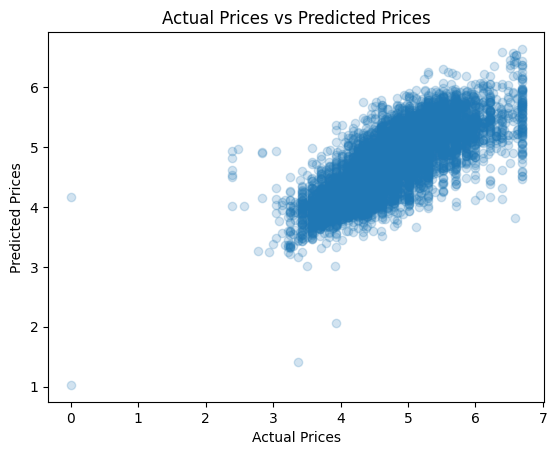

In [130]:
plt.scatter(y_test, y_pred, alpha = 0.2)
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual Prices vs Predicted Prices")
plt.show()

In [131]:
# eval
from sklearn.metrics import (mean_squared_error, root_mean_squared_error,
                             mean_absolute_error, r2_score, accuracy_score)

mse = mean_squared_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Random Forest Regression Metrics:")
print(f"MSE:  {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"MAE:  {mae:.2f}")
print(f"R2:   {r2:.4f}")

Random Forest Regression Metrics:
MSE:  0.17
RMSE: 0.41
MAE:  0.30
R2:   0.6269


In [132]:
from sklearn.linear_model import LinearRegression

model_pipeline_linear = Pipeline(steps = [
    ("preprocessor",preprocessor),
    ("model",LinearRegression())
])
model_pipeline_linear

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('log',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('log',
                                                                   FunctionTransformer(feature_names_out='one-to-one',
                                                                                       func=<ufunc 'log1p'>))]),
                                                  Index(['minimum_nights', 'number_of_reviews', 'reviews_per_month',
       'calculated_host_listings_count'],
      dtype='object')),
                                                 ('standard_pipeline',...
                                                                   SimpleImputer(strategy='median')),
                                                                  ('Scaling',
                                                                   StandardScaler())]),
                                                  ['latitude', 'longitude',
                                                   'availability_365']),
                                                 ('Categorical_Pipeline',
                                                  Pipeline(steps=[('Imputation_Step',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('Encoding_Step',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['neighbourhood_group', 'neighbourhood', 'room_type'], dtype='object'))])),
                ('model', LinearRegression())])

In [133]:
# Fit the linear pipeline first
model_pipeline_linear.fit(X_train, y_train)

# Make predictions
y_pred_l = model_pipeline_linear.predict(X_test)
y_pred_l

array([4.75511027, 3.89916768, 4.60013868, ..., 4.11172565, 5.33348614,
       4.76157142])

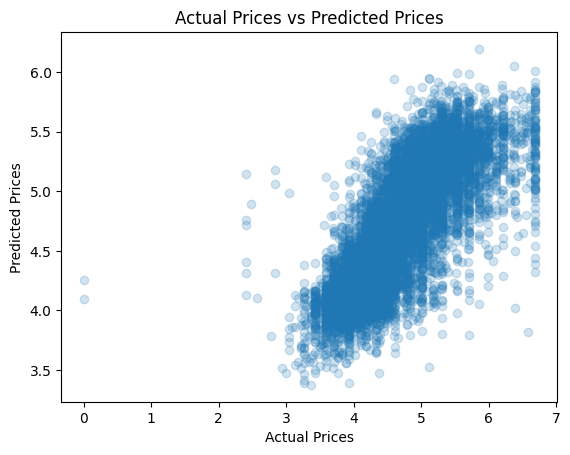

In [134]:
plt.scatter(y_test, y_pred_l, alpha = 0.2)
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual Prices vs Predicted Prices")
plt.show()

In [135]:
 # Evaluate the Linear Regression model metrics
mse_linear = mean_squared_error(y_test, y_pred_l)
rmse_linear = root_mean_squared_error(y_test, y_pred_l)
mae_linear = mean_absolute_error(y_test, y_pred_l)
r2_linear = r2_score(y_test, y_pred_l)

print(f"Linear Regression Metrics:")
print(f"MSE:  {mse_linear:.2f}")
print(f"RMSE: {rmse_linear:.2f}")
print(f"MAE:  {mae_linear:.2f}")
print(f"R2:   {r2_linear:.4f}")

Linear Regression Metrics:
MSE:  0.19
RMSE: 0.44
MAE:  0.32
R2:   0.5808
